INFORMACJE O ŚRODOWISKU
PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
OpenCV: 4.14.0
Urządzenie: cpu

WŁASNY MINI-ZBIÓR
kolo: 40 obrazów
kwadrat: 40 obrazów

IMAGEFOLDER
Klasy: ['kolo', 'kwadrat']
class_to_idx: {'kolo': 0, 'kwadrat': 1}
Liczba wszystkich obrazów: 80

PODZIAŁ DANYCH
Train: 64
Validation: 16
Train class counts: [32 32]
Validation class counts: [8 8]

STATYSTYKI


,klasa,class_to_idx,train,validation,źródłowy rozmiar,tensor
0,kolo,0,32,8,96×96 px,"(3, 64, 64)"
1,kwadrat,1,32,8,96×96 px,"(3, 64, 64)"


Liczba klas: 2
Liczba obrazów: 80
class_to_idx: {'kolo': 0, 'kwadrat': 1}

AUDYT PACZKI
Kształt paczki: (16, 3, 64, 64)
Typ tensora: torch.float32
Zakres wartości: -1.0 do 1.0
Etykiety: [0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1]
Nazwy klas: ['kolo', 'kwadrat', 'kwadrat', 'kwadrat', 'kwadrat', 'kwadrat', 'kwadrat', 'kolo', 'kolo', 'kolo', 'kolo', 'kolo', 'kolo', 'kwadrat', 'kolo', 'kwadrat']


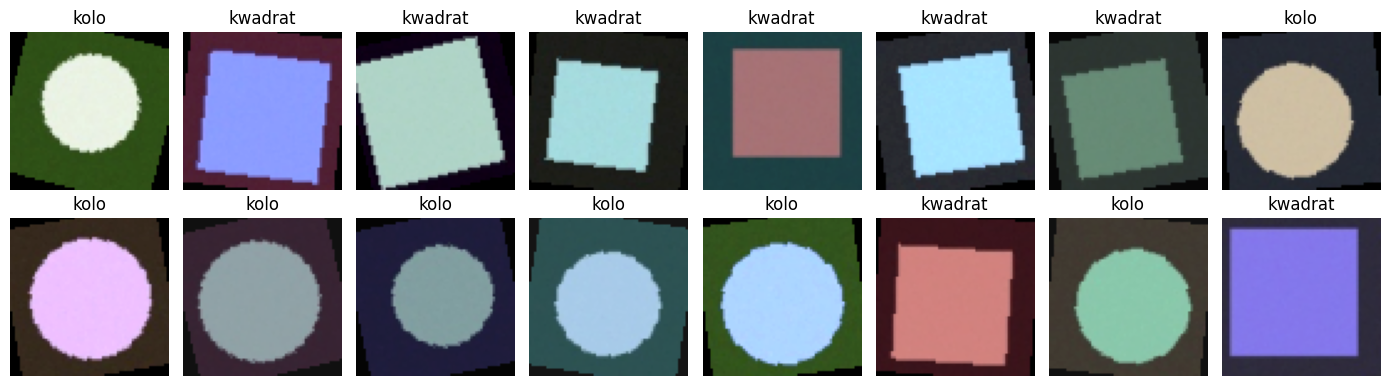

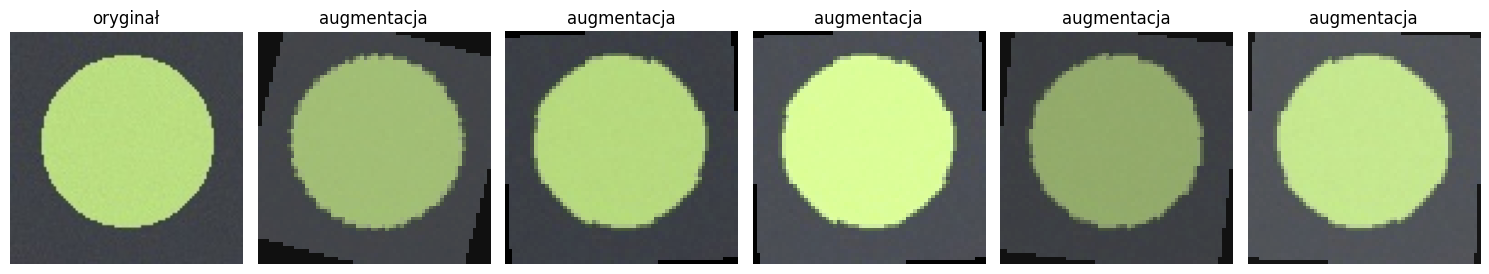


Przykładowy plik: dane_wlasne/kolo/kolo_000.jpg
Etykieta: 0 -> kolo

KONTROLA WYCIEKU DANYCH
Liczba wspólnych indeksów: 0
OK - brak wspólnych próbek.
OK - cały zbiór został podzielony.
Augmentacja występuje tylko w potoku treningowym.

OPIS UNIKANIA WYCIEKU

Dane zostały podzielone na train i validation
przed zastosowaniem losowej augmentacji.

Podział wykonano osobno dla każdej klasy
w proporcji 80/20.

Do zbioru treningowego trafiają wyłącznie
indeksy z train_idx, natomiast walidacja
korzysta wyłącznie z val_idx.

Dodatkowo sprawdzono przecięcie obu zbiorów.
Liczba wspólnych próbek wynosi 0.

Dzięki temu ten sam obraz nie występuje
jednocześnie w treningu i walidacji.

Augmentacja jest wykonywana tylko podczas
pobierania próbek ze zbioru treningowego.
Walidacja korzysta z deterministycznego
potoku ewaluacyjnego bez losowej augmentacji.


ŹRÓDŁO DANYCH I RODO

Źródłem danych są własne grafiki wygenerowane
lokalnie w Pythonie z wykorzystaniem biblioteki
Pillow.

Zbiór składa się z dwó

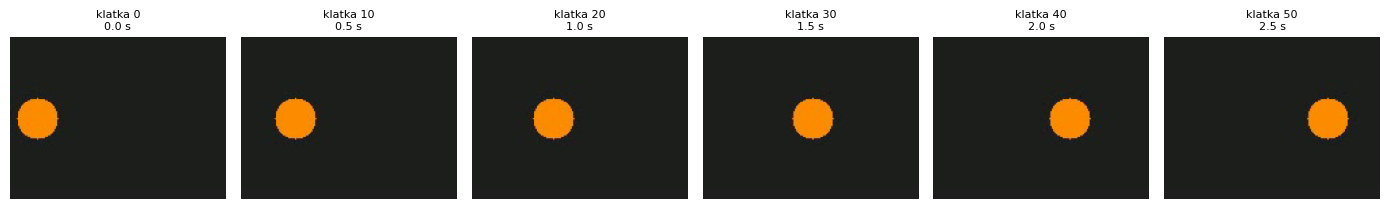

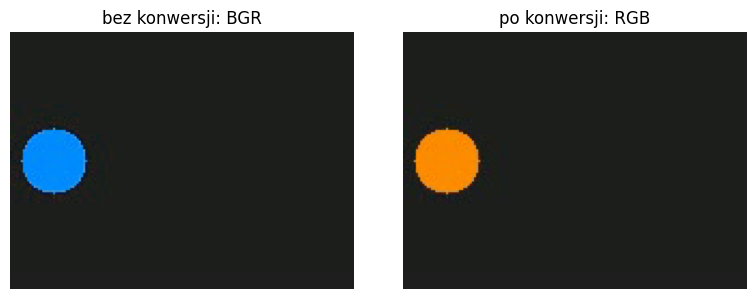


WPŁYW PARAMETRU EVERY


,every,liczba pobranych klatek,odstęp [s],czas filmu [s]
0,1,60,0.05,3.0
1,5,12,0.25,3.0
2,15,4,0.75,3.0
3,30,2,1.50,3.0



KLATKI WIDEO -> TENSORY
Liczba klatek: 6
Kształt paczki: (6, 3, 64, 64)
Typ: torch.float32
Zakres po normalizacji: -1.0 do 1.0

OK - klatki zostały poprawnie zamienione na tensory [T, C, H, W].

PODSUMOWANIE ZADANIA

1. Utworzono własny mini-zbiór obrazów:
   - 2 klasy,
   - 40 obrazów na klasę,
   - razem 80 obrazów.

2. Zastosowano ImageFolder.

3. Zastosowano dwa potoki transformacji:
   - treningowy z augmentacją,
   - walidacyjny bez augmentacji.

4. Zastosowane augmentacje:
   - RandomHorizontalFlip,
   - RandomRotation,
   - ColorJitter.

5. Dane podzielono w proporcji 80/20.

6. Zastosowano DataLoader:
   - batch_size=16,
   - shuffle=True dla treningu,
   - shuffle=False dla walidacji.

7. Sprawdzono:
   - liczbę klas,
   - liczbę obrazów,
   - class_to_idx,
   - rozmiar obrazów,
   - kształt tensorów,
   - typ danych,
   - zakres wartości,
   - etykiety.

8. Przeprowadzono audyt przykładowej paczki.

9. Sprawdzono brak wycieku danych pomiędzy train i validation.

10. Przeana

In [1]:


import os
import random
import shutil

import numpy as np
import pandas as pd
import cv2
import torch
import torchvision

from PIL import Image, ImageDraw
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Subset

import matplotlib.pyplot as plt



SEED = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("=" * 60)
print("INFORMACJE O ŚRODOWISKU")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("Urządzenie:", device)



ROOT = "dane_wlasne"

CLASSES = [
    "kolo",
    "kwadrat"
]

N_PER_CLASS = 40

SIZE = 96


if os.path.exists(ROOT):
    shutil.rmtree(ROOT)


def make_image(kind, size=SIZE):

    bg = tuple(
        np.random.randint(
            20,
            80,
            size=3
        ).tolist()
    )


    fg = tuple(
        np.random.randint(
            120,
            255,
            size=3
        ).tolist()
    )


    img = Image.new(
        "RGB",
        (size, size),
        bg
    )

    draw = ImageDraw.Draw(img)


    margin = int(
        np.random.randint(
            10,
            20
        )
    )


    x_shift = int(
        np.random.randint(
            -5,
            6
        )
    )

    y_shift = int(
        np.random.randint(
            -5,
            6
        )
    )

    box = [
        margin + x_shift,
        margin + y_shift,
        size - margin + x_shift,
        size - margin + y_shift
    ]


    if kind == "kolo":

        draw.ellipse(
            box,
            fill=fg
        )

    elif kind == "kwadrat":

        draw.rectangle(
            box,
            fill=fg
        )

    else:

        raise ValueError(
            "Nieznana klasa"
        )


    arr = np.array(
        img
    ).astype(
        np.int16
    )

    noise = np.random.normal(
        loc=0,
        scale=3,
        size=arr.shape
    )

    arr = np.clip(
        arr + noise,
        0,
        255
    ).astype(
        np.uint8
    )

    return Image.fromarray(
        arr
    )


for cls in CLASSES:

    class_dir = os.path.join(
        ROOT,
        cls
    )

    os.makedirs(
        class_dir,
        exist_ok=True
    )

    for i in range(
        N_PER_CLASS
    ):

        filename = (
            f"{cls}_{i:03d}.jpg"
        )

        path = os.path.join(
            class_dir,
            filename
        )

        make_image(
            cls
        ).save(
            path,
            quality=95
        )


print()
print("=" * 60)
print("WŁASNY MINI-ZBIÓR")
print("=" * 60)

for cls in CLASSES:

    class_dir = os.path.join(
        ROOT,
        cls
    )

    count = len(
        os.listdir(
            class_dir
        )
    )

    print(
        f"{cls}: {count} obrazów"
    )



eval_tf = transforms.Compose([

    transforms.Resize(
        (64, 64)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


train_tf = transforms.Compose([

    transforms.Resize(
        (64, 64)
    ),


    transforms.RandomHorizontalFlip(
        p=0.5
    ),


    transforms.RandomRotation(
        15
    ),


    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])



base_ds = datasets.ImageFolder(
    ROOT
)


print()
print("=" * 60)
print("IMAGEFOLDER")
print("=" * 60)

print(
    "Klasy:",
    base_ds.classes
)

print(
    "class_to_idx:",
    base_ds.class_to_idx
)

print(
    "Liczba wszystkich obrazów:",
    len(base_ds)
)



rng = np.random.default_rng(
    SEED
)

train_idx = []
val_idx = []



for class_id in range(
    len(base_ds.classes)
):

    idx = np.where(
        np.array(
            base_ds.targets
        ) == class_id
    )[0]

    rng.shuffle(
        idx
    )

    cut = int(
        0.8 * len(idx)
    )

    train_idx.extend(
        idx[:cut].tolist()
    )

    val_idx.extend(
        idx[cut:].tolist()
    )


train_idx = sorted(
    train_idx
)

val_idx = sorted(
    val_idx
)


train_full = datasets.ImageFolder(
    ROOT,
    transform=train_tf
)

val_full = datasets.ImageFolder(
    ROOT,
    transform=eval_tf
)


train_ds = Subset(
    train_full,
    train_idx
)

val_ds = Subset(
    val_full,
    val_idx
)


train_dl = DataLoader(
    train_ds,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_dl = DataLoader(
    val_ds,
    batch_size=16,
    shuffle=False,
    num_workers=0
)


print()
print("=" * 60)
print("PODZIAŁ DANYCH")
print("=" * 60)

print(
    "Train:",
    len(train_ds)
)

print(
    "Validation:",
    len(val_ds)
)


train_counts = np.bincount(
    np.array(
        base_ds.targets
    )[train_idx]
)

val_counts = np.bincount(
    np.array(
        base_ds.targets
    )[val_idx]
)


print(
    "Train class counts:",
    train_counts
)

print(
    "Validation class counts:",
    val_counts
)



source_sizes = []


for path, label in base_ds.samples:

    with Image.open(path) as im:

        source_sizes.append(
            (
                im.width,
                im.height
            )
        )


source_w = sorted(
    set(
        w
        for w, h in source_sizes
    )
)

source_h = sorted(
    set(
        h
        for w, h in source_sizes
    )
)


sample_tensor, sample_label = (
    train_ds[0]
)


targets = np.array(
    base_ds.targets
)


rows = []


for class_name, class_id in (
    base_ds.class_to_idx.items()
):

    rows.append({

        "klasa":
            class_name,

        "class_to_idx":
            class_id,

        "train":
            int(
                np.sum(
                    targets[train_idx]
                    == class_id
                )
            ),

        "validation":
            int(
                np.sum(
                    targets[val_idx]
                    == class_id
                )
            ),

        "źródłowy rozmiar":
            f"{source_w[0]}×{source_h[0]} px",

        "tensor":
            str(
                tuple(
                    sample_tensor.shape
                )
            )
    })


stats = pd.DataFrame(
    rows
)


print()
print("=" * 60)
print("STATYSTYKI")
print("=" * 60)

display(
    stats
)

print(
    "Liczba klas:",
    len(base_ds.classes)
)

print(
    "Liczba obrazów:",
    len(base_ds)
)

print(
    "class_to_idx:",
    base_ds.class_to_idx
)



xb, yb = next(
    iter(train_dl)
)


print()
print("=" * 60)
print("AUDYT PACZKI")
print("=" * 60)

print(
    "Kształt paczki:",
    tuple(
        xb.shape
    )
)

print(
    "Typ tensora:",
    xb.dtype
)

print(
    "Zakres wartości:",
    float(
        xb.min()
    ),
    "do",
    float(
        xb.max()
    )
)

print(
    "Etykiety:",
    yb.tolist()
)

print(
    "Nazwy klas:",
    [
        base_ds.classes[
            int(y)
        ]
        for y in yb
    ]
)


fig, axes = plt.subplots(
    2,
    8,
    figsize=(14, 4)
)


for ax, img, label in zip(
    axes.flat,
    xb,
    yb
):


    img_show = (
        img * 0.5 + 0.5
    ).clamp(
        0,
        1
    )

    ax.imshow(
        img_show.permute(
            1,
            2,
            0
        ).numpy()
    )

    ax.set_title(
        base_ds.classes[
            int(label)
        ]
    )

    ax.axis(
        "off"
    )


plt.tight_layout()
plt.show()


raw_path, raw_label = (
    base_ds.samples[0]
)


raw = Image.open(
    raw_path
).convert(
    "RGB"
)


fig, axes = plt.subplots(
    1,
    6,
    figsize=(15, 3)
)


axes[0].imshow(
    raw
)

axes[0].set_title(
    "oryginał"
)

axes[0].axis(
    "off"
)


for ax in axes[1:]:

    aug = train_tf(
        raw
    )

    img_show = (
        aug * 0.5 + 0.5
    ).clamp(
        0,
        1
    )

    ax.imshow(
        img_show.permute(
            1,
            2,
            0
        ).numpy()
    )

    ax.set_title(
        "augmentacja"
    )

    ax.axis(
        "off"
    )


plt.tight_layout()
plt.show()


print()
print(
    "Przykładowy plik:",
    raw_path
)

print(
    "Etykieta:",
    raw_label,
    "->",
    base_ds.classes[
        raw_label
    ]
)



intersection = (
    set(train_idx)
    &
    set(val_idx)
)


print()
print("=" * 60)
print("KONTROLA WYCIEKU DANYCH")
print("=" * 60)

print(
    "Liczba wspólnych indeksów:",
    len(intersection)
)


assert len(
    intersection
) == 0, (
    "Wykryto wyciek między "
    "train i validation!"
)


assert (
    len(train_idx)
    +
    len(val_idx)
    ==
    len(base_ds)
), (
    "Nie wszystkie próbki "
    "zostały przypisane!"
)


assert (
    set(
        train_full.class_to_idx.items()
    )
    ==
    set(
        val_full.class_to_idx.items()
    )
)


print(
    "OK - brak wspólnych próbek."
)

print(
    "OK - cały zbiór został podzielony."
)

print(
    "Augmentacja występuje tylko "
    "w potoku treningowym."
)



print()
print("=" * 60)
print("OPIS UNIKANIA WYCIEKU")
print("=" * 60)

print(
    """
Dane zostały podzielone na train i validation
przed zastosowaniem losowej augmentacji.

Podział wykonano osobno dla każdej klasy
w proporcji 80/20.

Do zbioru treningowego trafiają wyłącznie
indeksy z train_idx, natomiast walidacja
korzysta wyłącznie z val_idx.

Dodatkowo sprawdzono przecięcie obu zbiorów.
Liczba wspólnych próbek wynosi 0.

Dzięki temu ten sam obraz nie występuje
jednocześnie w treningu i walidacji.

Augmentacja jest wykonywana tylko podczas
pobierania próbek ze zbioru treningowego.
Walidacja korzysta z deterministycznego
potoku ewaluacyjnego bez losowej augmentacji.
"""
)


print()
print("=" * 60)
print("ŹRÓDŁO DANYCH I RODO")
print("=" * 60)

print(
    """
Źródłem danych są własne grafiki wygenerowane
lokalnie w Pythonie z wykorzystaniem biblioteki
Pillow.

Zbiór składa się z dwóch klas:
kolo oraz kwadrat.

Obrazy nie zawierają osób, wizerunków,
tablic rejestracyjnych ani innych danych
osobowych.

W przypadku wykorzystania prawdziwych zdjęć
lub nagrań zawierających osoby należy wskazać
podstawę prawną przetwarzania danych oraz
ograniczyć identyfikację do zakresu niezbędnego
do realizacji zadania.

Przy publikacji danych można zastosować
anonimizację, np. rozmycie twarzy lub tablic
rejestracyjnych.
"""
)


VIDEO = "demo.avi"

H = 120
W = 160

FPS = 20
N_FRAMES = 60



vw = cv2.VideoWriter(

    VIDEO,

    cv2.VideoWriter_fourcc(
        *"MJPG"
    ),

    FPS,

    (
        W,
        H
    )
)


for t in range(
    N_FRAMES
):


    frame = np.full(
        (
            H,
            W,
            3
        ),
        30,
        np.uint8
    )



    cx = int(
        20
        +
        (W - 40)
        *
        t
        /
        (N_FRAMES - 1)
    )



    cv2.circle(
        frame,
        (
            cx,
            H // 2
        ),
        15,
        (
            0,
            140,
            255
        ),
        -1
    )


    vw.write(
        frame
    )


vw.release()


print()
print("=" * 60)
print("WIDEO")
print("=" * 60)

print(
    "Zapisano:",
    VIDEO
)



def read_video_info(
    path
):

    cap = cv2.VideoCapture(
        path
    )


    fps = cap.get(
        cv2.CAP_PROP_FPS
    )


    total = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )


    width = int(
        cap.get(
            cv2.CAP_PROP_FRAME_WIDTH
        )
    )


    height = int(
        cap.get(
            cv2.CAP_PROP_FRAME_HEIGHT
        )
    )


    cap.release()


    return (
        fps,
        total,
        width,
        height
    )


fps, total, width, height = (
    read_video_info(
        VIDEO
    )
)


duration = (
    total / fps
    if fps
    else 0
)


print()
print(
    "FPS:",
    fps
)

print(
    "Liczba klatek:",
    total
)

print(
    "Rozdzielczość:",
    f"{width}×{height}"
)

print(
    f"Czas trwania: {duration:.2f} s"
)




def sample_frames(
    path,
    every=10
):

    cap = cv2.VideoCapture(
        path
    )


    fps = cap.get(
        cv2.CAP_PROP_FPS
    )


    total = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )


    frames = []

    frame_numbers = []

    i = 0


    while True:

        ok, frame_bgr = (
            cap.read()
        )


        if not ok:
            break



        if i % every == 0:



            frame_rgb = cv2.cvtColor(
                frame_bgr,
                cv2.COLOR_BGR2RGB
            )


            frames.append(
                frame_rgb
            )


            frame_numbers.append(
                i
            )


        i += 1


    cap.release()


    return (
        frames,
        frame_numbers,
        fps,
        total
    )



frames, frame_numbers, fps, total = (
    sample_frames(
        VIDEO,
        every=10
    )
)


print()
print("=" * 60)
print("PRÓBKOWANIE KLATEK")
print("=" * 60)

print(
    "Próbkowanie co 10. klatkę"
)

print(
    "Numery klatek:",
    frame_numbers
)

print(
    "Liczba pobranych klatek:",
    len(frames)
)

print(
    "Odstęp między próbkami:",
    f"{10 / fps:.3f} s"
)




fig, axes = plt.subplots(
    1,
    len(frames),
    figsize=(14, 2.5)
)


for ax, fr, idx in zip(
    axes,
    frames,
    frame_numbers
):

    ax.imshow(
        fr
    )

    ax.set_title(
        f"klatka {idx}\n"
        f"{idx / fps:.1f} s",
        fontsize=8
    )

    ax.axis(
        "off"
    )


plt.tight_layout()
plt.show()




cap = cv2.VideoCapture(
    VIDEO
)


ok, frame_bgr = (
    cap.read()
)


cap.release()


if not ok:

    raise RuntimeError(
        "Nie udało się odczytać "
        "pierwszej klatki."
    )


frame_rgb = cv2.cvtColor(
    frame_bgr,
    cv2.COLOR_BGR2RGB
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(8, 3)
)


axes[0].imshow(
    frame_bgr
)

axes[0].set_title(
    "bez konwersji: BGR"
)

axes[0].axis(
    "off"
)


axes[1].imshow(
    frame_rgb
)

axes[1].set_title(
    "po konwersji: RGB"
)

axes[1].axis(
    "off"
)


plt.tight_layout()
plt.show()




sampling_rows = []


for every in [
    1,
    5,
    15,
    30
]:

    _, nums, fps, total = (
        sample_frames(
            VIDEO,
            every=every
        )
    )


    sampling_rows.append({

        "every":
            every,

        "liczba pobranych klatek":
            len(nums),

        "odstęp [s]":
            every / fps,

        "czas filmu [s]":
            total / fps
    })


sampling_df = pd.DataFrame(
    sampling_rows
)


print()
print("=" * 60)
print("WPŁYW PARAMETRU EVERY")
print("=" * 60)

display(
    sampling_df
)



video_batch = torch.stack([

    eval_tf(
        Image.fromarray(
            fr
        )
    )

    for fr in frames

])


print()
print("=" * 60)
print("KLATKI WIDEO -> TENSORY")
print("=" * 60)

print(
    "Liczba klatek:",
    len(frames)
)

print(
    "Kształt paczki:",
    tuple(
        video_batch.shape
    )
)

print(
    "Typ:",
    video_batch.dtype
)

print(
    "Zakres po normalizacji:",
    float(
        video_batch.min()
    ),
    "do",
    float(
        video_batch.max()
    )
)




assert (
    video_batch.ndim
    == 4
)


assert (
    video_batch.shape[1]
    == 3
)


assert (
    video_batch.shape[2]
    == 64
)


assert (
    video_batch.shape[3]
    == 64
)


print()
print(
    "OK - klatki zostały poprawnie "
    "zamienione na tensory "
    "[T, C, H, W]."
)



print()
print("=" * 60)
print("PODSUMOWANIE ZADANIA")
print("=" * 60)

print(
    """
1. Utworzono własny mini-zbiór obrazów:
   - 2 klasy,
   - 40 obrazów na klasę,
   - razem 80 obrazów.

2. Zastosowano ImageFolder.

3. Zastosowano dwa potoki transformacji:
   - treningowy z augmentacją,
   - walidacyjny bez augmentacji.

4. Zastosowane augmentacje:
   - RandomHorizontalFlip,
   - RandomRotation,
   - ColorJitter.

5. Dane podzielono w proporcji 80/20.

6. Zastosowano DataLoader:
   - batch_size=16,
   - shuffle=True dla treningu,
   - shuffle=False dla walidacji.

7. Sprawdzono:
   - liczbę klas,
   - liczbę obrazów,
   - class_to_idx,
   - rozmiar obrazów,
   - kształt tensorów,
   - typ danych,
   - zakres wartości,
   - etykiety.

8. Przeprowadzono audyt przykładowej paczki.

9. Sprawdzono brak wycieku danych pomiędzy train i validation.

10. Przeanalizowano wideo:
    - FPS,
    - liczbę klatek,
    - czas trwania,
    - rozdzielczość.

11. Wykonano konwersję:
    BGR -> RGB.

12. Sprawdzono próbkowanie:
    every = 1, 5, 15, 30.

13. Klatki wideo przepuszczono przez preprocessing
    i zamieniono na tensory.

14. Nie wykonano treningu sieci,
    ponieważ zadanie dotyczy poprawności
    potoku danych i jego dokumentacji.
"""
)

print()
print("=" * 60)
print("ZADANIE ZAKOŃCZONE")
print("=" * 60)